# FarmTech Solutions · Fase 6 · "Ir Além" (opção 3.1)
## Detecção em tempo real de xícaras e tesouras com webcam / ESP32-CAM

**Grupo:** Lauren Cota (rm569789) · Jonathas Martins de Araujo (rm574051) · Carlos Magno Barcelos (rm569944)

**Objetivo.** Levar o modelo YOLOv5s treinado na Entrega 1 (`best.pt`, aqui `yolo_60ep.pt`) para fora do notebook de treino: um script em Python lê quadros de uma câmera em tempo real, aplica o modelo e desenha as detecções na tela. A câmera pode ser uma **webcam do PC** ou uma **ESP32-CAM** que transmite vídeo por Wi-Fi — o script aceita as duas só trocando um parâmetro.

> Este notebook documenta e justifica o projeto, mostra o código-fonte comentado, a figura de arquitetura e as evidências de resultado. A captura ao vivo em si roda **localmente** (a webcam do navegador/Colab não é acessível pelo script), conforme o passo a passo abaixo.

## 1. Justificativa da escolha

| Decisão | Por quê |
|---|---|
| **Reaproveitar o modelo da Entrega 1** | É o modelo selecionado pela validação (60 épocas, mAP@0.5:0.95 de teste 0,808). Mostra o ciclo completo: dados → treino → uso real. |
| **Webcam do PC como câmera principal** | O enunciado permite webcam conectada ao Python. Não exige compra de hardware e permite testar e gravar o vídeo com facilidade. |
| **Compatível com ESP32-CAM** | A ESP32-CAM é uma câmera de baixo custo (poucos dólares) com Wi-Fi embutido, adequada ao cenário da FarmTech: câmeras baratas espalhadas na fazenda enviando vídeo para um servidor que roda a IA. Ela publica um stream MJPEG por HTTP; o OpenCV lê essa URL como se fosse uma webcam (`--fonte http://IP:81/stream`). |
| **Processamento no PC e não na câmera** | O ESP32 não tem memória/CPU para uma YOLO. A câmera só captura e transmite; a inferência fica no computador. |
| **Entrada 320 px, confiança 0,5** | O mesmo tamanho do treino (320 px) e um limiar mais exigente que o da avaliação (0,25), para reduzir falsos positivos em ambiente aberto. |

> **Transparência:** o script foi escrito para ESP32-CAM, mas a demonstração do grupo usa a webcam do PC. A leitura do stream do ESP32 usa a mesma chamada do OpenCV (`cv2.VideoCapture(url)`), porém não foi testada com o hardware real.

## 2. Arquitetura do sistema

In [1]:
# Localiza a pasta "FASE 6" do repositório (no Colab, clona o GitHub se ainda não existir)
from pathlib import Path
import json, subprocess, textwrap
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Markdown

def achar_raiz():
    """Sobe a partir da pasta atual até achar a pasta que contém assets/modelos."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "assets" / "modelos").exists():
            return base
    # fallback para o Colab: clona só o necessário do repositório público do grupo
    repo = Path("repo_fase6")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/jonathasArauj/FIAP_IA_TURMAB_GRUPO_BH_MG2", str(repo)], check=True)
    return repo / "ANO1" / "FASE 6"

RAIZ = achar_raiz()
IA = RAIZ / "ir_alem"          # pasta deste "Ir Além"
print("Raiz da Fase 6:", RAIZ.resolve().name, "| Pesos disponíveis:", sorted(p.name for p in (RAIZ/"assets"/"modelos").glob("*.pt")))

Raiz da Fase 6: FASE 6 | Pesos disponíveis: ['yolo_30ep.pt', 'yolo_60ep.pt']


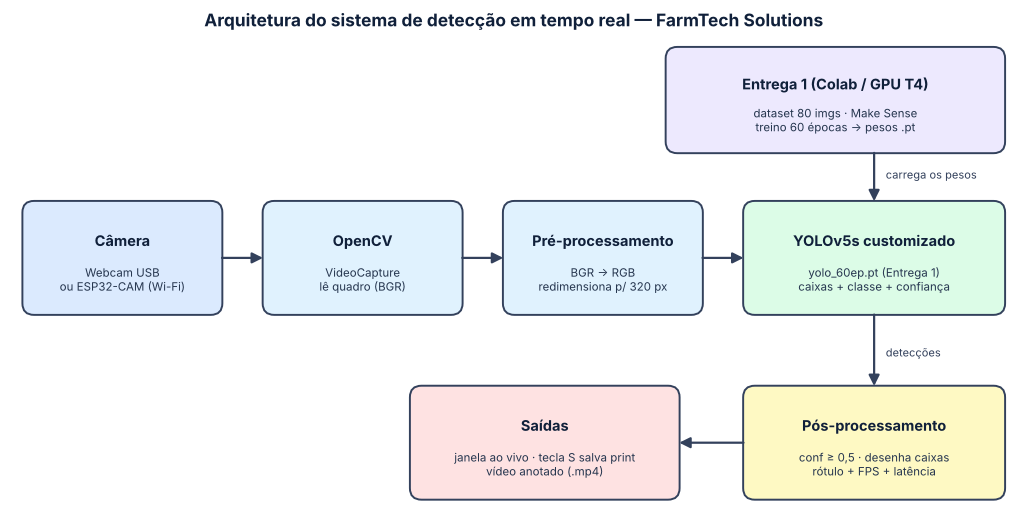

In [2]:
# Figura autoral da arquitetura: da câmera até a tela, passando pelo modelo da Entrega 1
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 6.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off")

def caixa(x, y, w, h, titulo, detalhe, cor):
    """Desenha um bloco arredondado com título e detalhe."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.15",
                                fc=cor, ec="#33415c", lw=1.4))
    ax.text(x + w/2, y + h*0.66, titulo, ha="center", va="center", fontsize=10.5, weight="bold", color="#10203a")
    ax.text(x + w/2, y + h*0.30, detalhe, ha="center", va="center", fontsize=8.3, color="#26364f")

def seta(x1, y1, x2, y2, texto=""):
    """Desenha uma seta entre blocos, com legenda opcional."""
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=16, lw=1.6, color="#33415c"))
    if texto:
        ax.text((x1+x2)/2, y1 + 0.22, texto, ha="center", fontsize=7.8, color="#33415c")

# Faixa do meio: fluxo em tempo real (executado no PC)
caixa(0.2, 2.6, 2.5, 1.4, "Câmera", "Webcam USB\nou ESP32-CAM (Wi-Fi)", "#dbeafe")
caixa(3.3, 2.6, 2.5, 1.4, "OpenCV", "VideoCapture\nlê quadro (BGR)", "#e0f2fe")
caixa(6.4, 2.6, 2.5, 1.4, "Pré-processamento", "BGR → RGB\nredimensiona p/ 320 px", "#e0f2fe")
caixa(9.5, 2.6, 3.3, 1.4, "YOLOv5s customizado", "yolo_60ep.pt (Entrega 1)\ncaixas + classe + confiança", "#dcfce7")
seta(2.7, 3.3, 3.3, 3.3); seta(5.8, 3.3, 6.4, 3.3); seta(8.9, 3.3, 9.5, 3.3)

# Origem do modelo (Entrega 1), acima do bloco do YOLO
caixa(8.5, 4.7, 4.3, 1.3, "Entrega 1 (Colab / GPU T4)", "dataset 80 imgs · Make Sense\ntreino 60 épocas → pesos .pt", "#ede9fe")
seta(11.15, 4.7, 11.15, 4.0)
ax.text(11.3, 4.33, "carrega os pesos", fontsize=8, color="#33415c")

# Saída
caixa(9.5, 0.2, 3.3, 1.4, "Pós-processamento", "conf ≥ 0,5 · desenha caixas\nrótulo + FPS + latência", "#fef9c3")
caixa(5.2, 0.2, 3.4, 1.4, "Saídas", "janela ao vivo · tecla S salva print\nvídeo anotado (.mp4)", "#fee2e2")
seta(11.15, 2.6, 11.15, 1.6); ax.text(11.3, 2.02, "detecções", fontsize=8, color="#33415c")
seta(9.5, 0.9, 8.6, 0.9)

ax.set_title("Arquitetura do sistema de detecção em tempo real — FarmTech Solutions", fontsize=12.5, weight="bold", color="#10203a", pad=6)
(IA/"assets").mkdir(parents=True, exist_ok=True)
fig.savefig(IA/"assets"/"01_arquitetura.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 3. Código-fonte (comentado)

O código está em [`detector_webcam.py`](detector_webcam.py). Ele é carregado a seguir para ficar documentado dentro do notebook. Pontos de destaque:

- `torch.hub.load(...:COMMIT, "custom", path=pesos)` usa **o mesmo commit do YOLOv5** do treino, evitando incompatibilidade de versão.
- `abrir_fonte` aceita índice de webcam, URL de stream (ESP32-CAM) ou arquivo de vídeo.
- A conversão BGR→RGB é necessária porque o OpenCV entrega BGR e o YOLOv5 espera RGB.
- Cada quadro mede a **latência do modelo** e o **FPS** acumulado, exibidos na imagem.

In [3]:
# Exibe o código-fonte do detector, já com os comentários linha a linha
codigo = (IA / "src" / "detector_webcam.py").read_text(encoding="utf-8")
print(f"detector_webcam.py — {len(codigo.splitlines())} linhas\n" + "-"*60)
print(codigo)

detector_webcam.py — 127 linhas
------------------------------------------------------------
# -*- coding: utf-8 -*-
"""
Ir Além (opção 3.1) - Detecção em tempo real de xícaras e tesouras.

Lê quadros de uma webcam do PC, de uma câmera ESP32-CAM (stream MJPEG via Wi-Fi)
ou de um arquivo de vídeo, e aplica o modelo YOLOv5s treinado na Entrega 1
(arquivo de pesos .pt, o "best.pt" do treino de 60 épocas).

Exemplos de uso (rode a partir da pasta ir_alem/src):
    python detector_webcam.py                              # webcam padrão (índice 0)
    python detector_webcam.py --fonte 1                    # segunda webcam
    python detector_webcam.py --fonte http://192.168.0.50:81/stream   # ESP32-CAM
    python detector_webcam.py --fonte video.mp4 --sem-janela --saida resultado.mp4

Teclas na janela: Q ou ESC = sair | S = salvar o quadro atual em PNG.
"""
import argparse                      # leitura dos parâmetros de linha de comando
import time                          # medição de tempo

## 4. Como executar localmente (VS Code / terminal)

```bash
# 1) Clonar o repositório e entrar na pasta do Ir Além
git clone https://github.com/jonathasArauj/FIAP_IA_TURMAB_GRUPO_BH_MG2
cd "FIAP_IA_TURMAB_GRUPO_BH_MG2/ANO1/FASE 6/ir_alem/src"

# 2) Instalar as dependências (ambiente virtual recomendado)
pip install -r ../requirements_ir_alem.txt

# 3) Rodar com a webcam do PC
python detector_webcam.py

# 3b) Ou com uma ESP32-CAM na mesma rede Wi-Fi (URL do stream do sketch CameraWebServer)
python detector_webcam.py --fonte http://192.168.0.50:81/stream

# 3c) Ou gravando o vídeo anotado, sem abrir janela (útil para testar)
python detector_webcam.py --fonte meu_video.mp4 --sem-janela --saida resultado.mp4
```

Teclas na janela: **Q** ou **ESC** sai · **S** salva o quadro atual em `prints/`.
Na primeira execução o `torch.hub` baixa o código do YOLOv5 (precisa de internet).

## 5. Resultados e evidências

### 5.1 Desempenho do modelo usado (medido na Entrega 1)
O detector em tempo real usa exatamente o modelo de 60 épocas avaliado no conjunto de teste (8 imagens nunca vistas no treino).

In [4]:
# Lê os resultados oficiais da Entrega 1 e mostra o desempenho do modelo usado na câmera
import pandas as pd
res = json.loads((RAIZ / "assets" / "resultados.json").read_text(encoding="utf-8"))
e1 = pd.DataFrame(res["entrega1"])
modelo_camera = e1[(e1["treino"] == "60 épocas")].set_index("etapa")
tabela = modelo_camera[["precisão", "recall", "mAP@0.5", "mAP@0.5:0.95"]].round(3)
display(tabela)

# Latência medida (CPU, do arquivo até a classe, batch 1) — base para estimar o FPS em tempo real
lat = pd.Series(res["latencias_ms"]["YOLO customizado"])
print(f"Latência CPU do YOLO customizado: média {lat.mean():.0f} ms | mediana {lat.median():.0f} ms | p95 {lat.quantile(.95):.0f} ms")
print(f"FPS estimado em CPU: ~{1000/lat.mean():.0f} (pela média) a ~{1000/lat.median():.0f} (pela mediana)")

Latência CPU do YOLO customizado: média 157 ms | mediana 103 ms | p95 413 ms
FPS estimado em CPU: ~6 (pela média) a ~10 (pela mediana)


,precisão,recall,mAP@0.5,mAP@0.5:0.95
etapa,,,,
validação,0.964,1.0,0.995,0.783
teste,0.980,1.0,0.995,0.808


### 5.2 Detecções do modelo nas imagens de teste
Saídas reais do modelo de 60 épocas nas 8 imagens de teste (xícara e tesoura), as mesmas que o detector em tempo real processa quadro a quadro.

8 imagens de teste exibidas


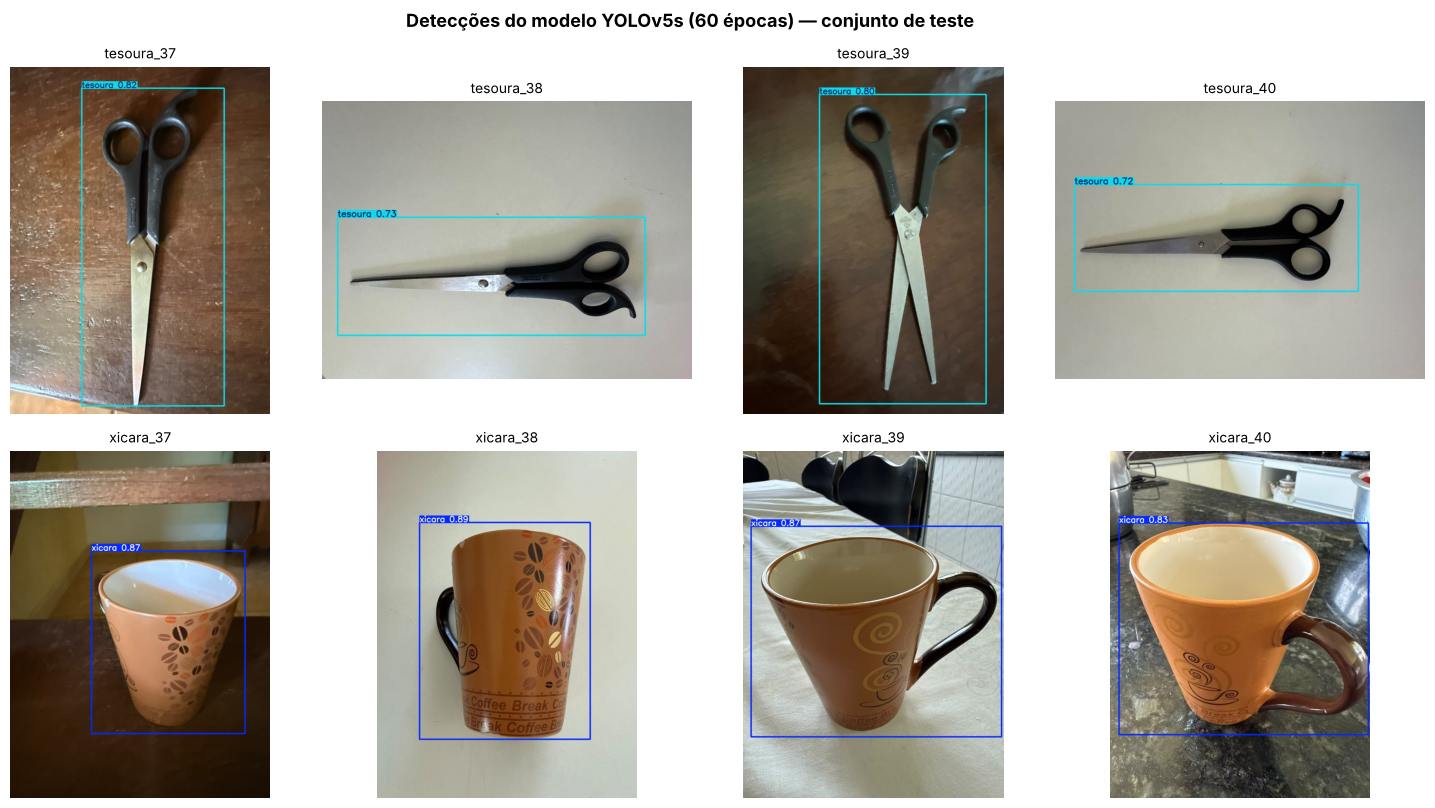

In [5]:
# Mosaico com as 8 detecções do modelo de 60 épocas nas imagens de teste
import matplotlib.pyplot as plt
arqs = sorted((RAIZ / "assets" / "imagens" / "detect_60ep").glob("*.jpg"))
fig, axs = plt.subplots(2, 4, figsize=(15, 8.2))
for ax, arq in zip(axs.ravel(), arqs):
    ax.imshow(mpimg.imread(arq)); ax.set_title(arq.stem, fontsize=10); ax.axis("off")
fig.suptitle("Detecções do modelo YOLOv5s (60 épocas) — conjunto de teste", fontsize=13, weight="bold")
plt.tight_layout()
fig.savefig(IA/"assets"/"02_deteccoes_modelo_60ep.png", dpi=110, bbox_inches="tight", facecolor="white")
plt.show()
print(len(arqs), "imagens de teste exibidas")

### 5.3 Prints da captura ao vivo (webcam)
Os prints abaixo são gerados pela tecla **S** do script (pasta `prints/`) durante a gravação do vídeo e ficam em [`assets/prints_webcam/`](../assets/prints_webcam/).

In [6]:
# Mostra os prints da webcam, se já tiverem sido adicionados à pasta assets/prints_webcam
prints = sorted((IA / "assets" / "prints_webcam").glob("*.png")) + sorted((IA / "assets" / "prints_webcam").glob("*.jpg"))
if prints:
    fig, axs = plt.subplots(1, min(len(prints), 3), figsize=(5.2*min(len(prints), 3), 4.4), squeeze=False)
    for ax, arq in zip(axs.ravel(), prints[:3]):
        ax.imshow(mpimg.imread(arq)); ax.set_title(arq.name, fontsize=9); ax.axis("off")
    plt.show()
else:
    print("Nenhum print da webcam adicionado ainda — salvar com a tecla S durante a demonstração e colocar em assets/prints_webcam/.")

Nenhum print da webcam adicionado ainda — salvar com a tecla S durante a demonstração e colocar em assets/prints_webcam/.


## 6. Análise crítica

In [7]:
# Análise gerada a partir dos números medidos, para o texto sempre bater com os resultados
br = lambda v, c=3: f"{v:.{c}f}".replace(".", ",")
t = modelo_camera.loc["teste"]
fps_lo, fps_hi = 1000/lat.mean(), 1000/lat.median()
display(Markdown(f"""
**Pontos fortes**
- **Reuso direto da Entrega 1:** o mesmo arquivo de pesos vira uma aplicação em tempo real, sem retreinar. No teste, o modelo obteve mAP@0,5 de **{br(t['mAP@0.5'])}**, precisão de **{br(t['precisão'])}** e recall de **{br(t['recall'])}**.
- **Fluxo simples e portátil:** câmera → OpenCV → YOLOv5 → tela. Trocar webcam por ESP32-CAM exige só mudar `--fonte`.
- **Custo baixo de câmera:** a ESP32-CAM só captura e transmite, enquanto a IA roda no PC.
- **Resultados mensuráveis:** cada quadro mostra a latência e o FPS, o que permite avaliar se o sistema atende o cenário.

**Limitações e riscos**
- **Velocidade em CPU:** a latência medida na Entrega 1 (média de {lat.mean():.0f} ms) indica algo como **{fps_lo:.0f} a {fps_hi:.0f} quadros por segundo** em CPU; é suficiente para monitorar objetos parados, mas não para movimento rápido. Uma GPU reduz a latência a poucos milissegundos (na avaliação em GPU T4 o modelo levou {br(t['inferência (ms/img)'],1)} ms por imagem).
- **Dataset pequeno:** o treino usou 64 imagens e o teste apenas 8; luz, ângulo, fundo e objetos diferentes das fotos podem reduzir a acurácia na câmera real. As métricas do teste indicam tendência, não garantia.
- **Só duas classes:** o modelo não reconhece outros objetos e pode confundir objetos parecidos com xícara ou tesoura; por isso o limiar foi elevado para 0,5.
- **ESP32-CAM não testada em hardware real:** a compatibilidade vem do uso de stream MJPEG via OpenCV; a estabilidade do Wi-Fi (perda de quadros, atraso) ainda precisa ser avaliada em campo.
- **Rede e segurança:** o stream da ESP32-CAM sem autenticação só deve circular em rede local confiável.

**Próximos passos:** ampliar o dataset com fotos da câmera real, testar a ESP32-CAM de verdade e avaliar exportar o modelo para ONNX para ganhar velocidade em CPU.
"""))


**Pontos fortes**
- **Reuso direto da Entrega 1:** o mesmo arquivo de pesos vira uma aplicação em tempo real, sem retreinar. No teste, o modelo obteve mAP@0,5 de **0,995**, precisão de **0,980** e recall de **1,000**.
- **Fluxo simples e portátil:** câmera → OpenCV → YOLOv5 → tela. Trocar webcam por ESP32-CAM exige só mudar `--fonte`.
- **Custo baixo de câmera:** a ESP32-CAM só captura e transmite, enquanto a IA roda no PC.
- **Resultados mensuráveis:** cada quadro mostra a latência e o FPS, o que permite avaliar se o sistema atende o cenário.

**Limitações e riscos**
- **Velocidade em CPU:** a latência medida na Entrega 1 (média de 157 ms) indica algo como **6 a 10 quadros por segundo** em CPU; é suficiente para monitorar objetos parados, mas não para movimento rápido. Uma GPU reduz a latência a poucos milissegundos (na avaliação em GPU T4 o modelo levou 1,6 ms por imagem).
- **Dataset pequeno:** o treino usou 64 imagens e o teste apenas 8; luz, ângulo, fundo e objetos diferentes das fotos podem reduzir a acurácia na câmera real. As métricas do teste indicam tendência, não garantia.
- **Só duas classes:** o modelo não reconhece outros objetos e pode confundir objetos parecidos com xícara ou tesoura; por isso o limiar foi elevado para 0,5.
- **ESP32-CAM não testada em hardware real:** a compatibilidade vem do uso de stream MJPEG via OpenCV; a estabilidade do Wi-Fi (perda de quadros, atraso) ainda precisa ser avaliada em campo.
- **Rede e segurança:** o stream da ESP32-CAM sem autenticação só deve circular em rede local confiável.

**Próximos passos:** ampliar o dataset com fotos da câmera real, testar a ESP32-CAM de verdade e avaliar exportar o modelo para ONNX para ganhar velocidade em CPU.
